# 7장. 그래프로 데이터의 이야기를 보여주기

이 노트북의 목표는 그래프를 많이 만드는 것이 아닙니다. **분석 질문에 맞는 그래프를 선택하고, 그래프에 들어간 데이터 범위와 수치를 검증하며, 그래프가 보여 주는 사실과 보여 주지 못하는 것을 구분하는 것**이 핵심입니다.

금액성 그래프는 기본적으로 `order_status == "completed"` 범위를 사용합니다. `line_total`은 주문 상세 한 행의 `quantity × unit_price`이며 회계상 순매출로 단정하지 않습니다.

## 제출 정보
- 이름: 김용준
- GitHub ID: rotcev40
- 작성일: 2026-10-28
- 최종 Notebook URL: https://github.com/rotcev40/llm-data-analysis-study/blob/main/chapter07/chapter07.ipynb

## 0. 사용 방법

- 위에서부터 차례대로 실행합니다.
- 입력은 Chapter 05에서 만든 `data/processed/*_clean.csv`입니다.
- 파일이 없다면 프로젝트 루트에서 `python scripts/preprocess_data.py`를 먼저 실행합니다.
- 그래프를 보기 전에 **시각화용 집계 검증표**를 먼저 확인합니다.
- 대표 그래프마다 `관찰 → 해석 → 한계 → 다음 질문`을 Markdown 셀에 직접 작성합니다.
- 실제 실행 결과 숫자를 보고 작성하며 강의안의 예시를 정답처럼 사용하지 않습니다.

## 1. 질문에 맞는 그래프를 먼저 고릅니다

| 분석 질문 | 그래프 | 데이터 범위 |
| --- | --- | --- |
| 카테고리별 완료 주문 금액은 어떻게 다른가? | 막대그래프 | completed 주문 상세 |
| 월별 완료 주문 금액은 어떻게 변하는가? | 선그래프 | completed + 유효한 주문일 |
| 상품 가격은 어느 구간에 몰려 있는가? | 히스토그램 | 전체 상품 마스터 |
| 상품 가격과 완료 주문 판매 수량은 어떤 패턴인가? | 산점도 | completed 상품 집계 |
| 완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가? | 가로 막대그래프 | completed 고객 집계 |
| 주문 상태별 주문 수는 어떻게 다른가? | 막대그래프 | 전체 orders |

> 그래프 종류보다 먼저 **질문과 데이터 범위**를 고정합니다.

## 1. 시각화 질문과 그래프 선택
| 질문 | 선택한 그래프 | 선택 이유 |
| --- | --- | --- |
| 카테고리별 completed 주문 금액은 어떻게 다른가 | 막대그래프 | 범주끼리 크기를 비교하는 질문이라 막대 길이로 바로 비교할 수 있다. y축이 0부터 시작해서 길이 비율이 금액 비율과 같다 |
| 월별 completed 주문 금액은 시간에 따라 어떻게 변하는가 | 선그래프 | 시간 순서가 있는 값이라 점을 이어 흐름을 보는 게 맞다. 다만 빈 달이 있으면 선이 그냥 이어지므로 따로 확인했다 |
| 상품 가격이 높을수록 completed 판매 수량이 적은가 | 산점도 | 숫자 변수 두 개의 관계를 보는 질문이라 상품 하나를 점 하나로 찍었다. 막대나 선으로는 두 변수를 같이 볼 수 없다 |

In [1]:
from pathlib import Path
import sys

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("현재 실행 위치:", CURRENT_DIR)
print("프로젝트 루트:", PROJECT_ROOT)
print("전처리 데이터 폴더:", PROCESSED_DIR)
print("그래프 저장 폴더:", FIGURE_DIR)

현재 실행 위치: C:\Users\yjun0\Desktop\서울대\4학년\2학기\LLM을 이용한 빅데이터 분석\llm-data-analysis-course\notebooks
프로젝트 루트: C:\Users\yjun0\Desktop\서울대\4학년\2학기\LLM을 이용한 빅데이터 분석\llm-data-analysis-course
전처리 데이터 폴더: C:\Users\yjun0\Desktop\서울대\4학년\2학기\LLM을 이용한 빅데이터 분석\llm-data-analysis-course\data\processed
그래프 저장 폴더: C:\Users\yjun0\Desktop\서울대\4학년\2학기\LLM을 이용한 빅데이터 분석\llm-data-analysis-course\reports\figures


## 2. 검증된 시각화용 데이터를 준비합니다

공통 모듈은 그래프를 그리기 전에 다음을 검사합니다.

- 필수 컬럼
- PK 결측·중복
- `many_to_one` 병합
- 주문/상품 미매칭
- 숫자형 변환 실패
- `completed` 주문 범위
- 카테고리·상품·고객·월별 집계 총합

문제가 있으면 그래프를 만들기 전에 중단합니다.

In [2]:
# 공식 함수가 관계 오류(주문 정보 없음, 상품 정보 없음)가 있으면 멈춰서
# 그래프용 입력에서 뺄 행을 먼저 따로 분리하고 기록한다. processed 원본은 그대로 둔다.
import pandas as pd

ch07_customers = pd.read_csv(PROCESSED_DIR / "customers_clean.csv")
ch07_products = pd.read_csv(PROCESSED_DIR / "products_clean.csv")
ch07_orders = pd.read_csv(PROCESSED_DIR / "orders_clean.csv")
ch07_items = pd.read_csv(PROCESSED_DIR / "order_items_clean.csv")

check = ch07_items.merge(
    ch07_orders[["order_id", "order_status"]],
    on="order_id",
    how="left",
    indicator=True,
)

no_order = check["_merge"].ne("both")
no_product = check["order_status"].eq("completed") & ~check["product_id"].isin(ch07_products["product_id"])

check["reason"] = None
check.loc[no_product, "reason"] = "completed인데 products에 없는 상품"
check.loc[no_order, "reason"] = "orders에 없는 주문"
excluded = check[check["reason"].notna()]

display(
    excluded.groupby("reason", as_index=False)
    .agg(row_count=("line_total", "size"), amount=("line_total", "sum"))
)
print("제외 product_id:", sorted(excluded["product_id"].unique()))

completed_before = check.loc[check["order_status"].eq("completed"), "line_total"].sum()
completed_after = completed_before - excluded.loc[excluded["order_status"].eq("completed"), "line_total"].sum()
print("processed 기준 completed 합계:", completed_before)
print("그래프 입력 기준 completed 합계:", completed_after)

CH07_INPUT_DIR = PROJECT_ROOT / "data" / "processed_ch07"
CH07_INPUT_DIR.mkdir(exist_ok=True)

ch07_customers.to_csv(CH07_INPUT_DIR / "customers_clean.csv", index=False, encoding="utf-8-sig")
ch07_products.to_csv(CH07_INPUT_DIR / "products_clean.csv", index=False, encoding="utf-8-sig")
ch07_orders.to_csv(CH07_INPUT_DIR / "orders_clean.csv", index=False, encoding="utf-8-sig")
ch07_items[~ch07_items["order_item_id"].isin(excluded["order_item_id"])].to_csv(
    CH07_INPUT_DIR / "order_items_clean.csv", index=False, encoding="utf-8-sig"
)

print("그래프용 order_items:", len(ch07_items) - len(excluded), "행 /", "원래", len(ch07_items), "행")

,reason,row_count,amount
0,completed인데 products에 없는 상품,16,4015000.0
1,orders에 없는 주문,2,922000.0


제외 product_id: [np.int64(18), np.int64(48), np.int64(73), np.int64(89), np.int64(95), np.int64(98), np.int64(9991)]
processed 기준 completed 합계: 141340000.0
그래프 입력 기준 completed 합계: 137325000.0
그래프용 order_items: 734 행 / 원래 752 행


In [3]:
from src.visualization import (
    prepare_visualization_data,
    setup_korean_font,
)

selected_font = setup_korean_font()
print("사용 한글 폰트:", selected_font or "자동 선택 실패 — 설치된 한글 폰트 확인 필요")

viz_data = prepare_visualization_data(CH07_INPUT_DIR)

products = viz_data["products"]
orders = viz_data["orders"]
completed_order_sales = viz_data["completed_order_sales"]
category_sales = viz_data["category_sales"]
monthly_sales = viz_data["monthly_sales"]
product_sales = viz_data["product_sales"]
customer_sales = viz_data["customer_sales"]
order_status = viz_data["order_status"]

print("완료 주문 상세 행:", len(completed_order_sales))
print(
    "월별 집계에서 제외되는 날짜 결측 완료 주문 상세:",
    len(viz_data["invalid_date_sales"]),
)

사용 한글 폰트: Malgun Gothic


완료 주문 상세 행: 430
월별 집계에서 제외되는 날짜 결측 완료 주문 상세: 6


In [4]:
viz_data["visualization_validation"]

,check,expected,actual,difference,passed
0,category_completed_amount,137325000.0,137325000.0,0.0,True
1,product_completed_amount,137325000.0,137325000.0,0.0,True
2,customer_completed_amount,137325000.0,137325000.0,0.0,True
3,monthly_completed_amount_valid_dates,135422000.0,135422000.0,0.0,True


### 검증 결과 기록

`passed`가 모두 `True`인지 확인한 뒤 아래 내용을 자신의 말로 작성합니다.

- 총합 검증 결과: 네 항목 모두 passed가 True다. 카테고리/상품/고객 기준은 137325000으로 같고, 월별은 날짜가 있는 행만 세서 135422000이다.
- 문제가 있었다면 원인: 처음 실행했을 때는 검증표가 나오기 전에 함수가 멈췄다. orders에 없는 주문 상세 2행(order_id 9991, 9992)과 completed인데 products에 없는 상품 16행 때문이다. 상품 쪽 16행 중 15행은 Chapter 05에서 price 문제로 지운 상품 18, 48, 73, 95이고 1행은 원래 없던 9991이다.
- 시각화를 진행해도 된다고 판단한 이유: 제외한 18행을 따로 표로 남기고 금액을 확인했다. 주문 정보가 없는 2행은 order_status가 없어서 어차피 completed 범위에 들어갈 수 없다. 상품 정보가 없는 16행은 카테고리를 알 수 없어서 카테고리 그래프에 넣을 방법이 없다. 대신 그래프 기준 completed 합계가 137325000으로 processed 기준 141340000보다 4015000 작다는 걸 알고 진행한다.

## 3. 카테고리별 완료 주문 금액 — 막대그래프

범주별 크기 비교이므로 막대그래프를 사용합니다. 값 축은 0에서 시작합니다. 금액이 크다는 사실만으로 선호도가 높다고 단정하지 않습니다.

In [5]:
from src.visualization import plot_category_sales

category_sales[["category", "total_quantity", "completed_amount", "amount_ratio_pct"]]

,category,total_quantity,completed_amount,amount_ratio_pct
9,패션,290.0,32940000.0,23.99
6,식품,226.0,25035000.0,18.23
8,전자기기,176.0,21485000.0,15.65
0,도서,174.0,17663000.0,12.86
2,뷰티,168.0,17103000.0,12.45
5,스포츠,165.0,13237000.0,9.64
4,생활용품,108.0,7001000.0,5.10
3,생활 용품,17.0,2108000.0,1.54
1,뷰 티,12.0,648000.0,0.47
7,전자 기기,5.0,105000.0,0.08


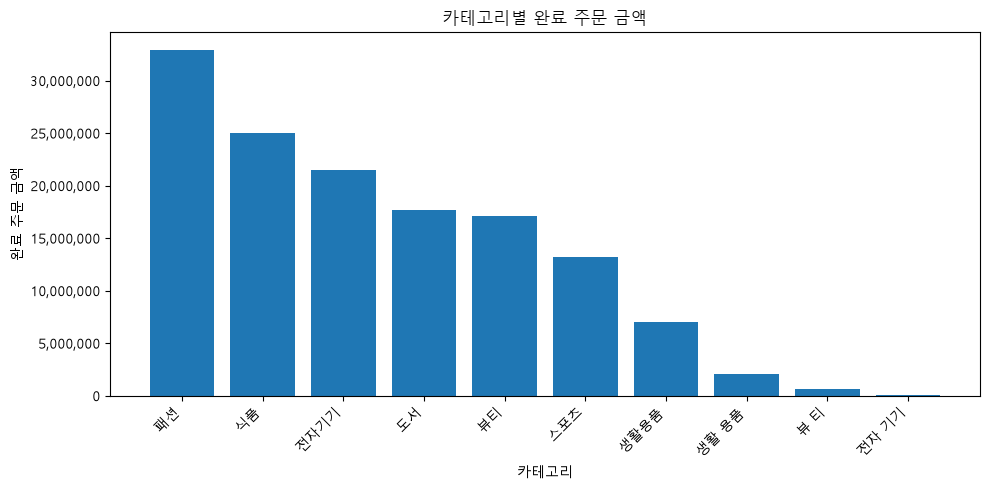

WindowsPath('C:/Users/yjun0/Desktop/서울대/4학년/2학기/LLM을 이용한 빅데이터 분석/llm-data-analysis-course/reports/figures/ch07_category_completed_amount_bar.png')

In [6]:
category_path = plot_category_sales(
    category_sales,
    FIGURE_DIR / "ch07_category_completed_amount_bar.png",
    show=True,
)
category_path

### 그래프 1 기록

- **관찰:** 패션이 32940000으로 가장 크고 식품 25035000, 전자기기 21485000 순이다. 막대가 10개인데 생활 용품, 뷰 티, 전자 기기는 띄어쓰기만 다른 이름이 따로 막대가 됐다.
- **해석:** 위 3개는 차이가 커서 표기 문제와 상관없이 순서가 유지된다. 4위 도서 17663000과 5위 뷰티 17103000은 560000 차이인데, 뷰 티 648000을 뷰티에 합치면 순서가 뒤집힌다.
- **한계:** 금액만 봐서 많이 팔린 건지 비싼 걸 판 건지 알 수 없다. 상품 정보가 없어 빠진 4015000이 어느 카테고리인지도 모른다.
- **다음 질문:** 카테고리별 금액을 판매 수량과 평균 단가로 나누면 어느 쪽 차이가 큰가?

## 2. 대표 그래프 1
![대표 그래프 1](images/graph01.png)

### 원본 집계값

| category | completed_amount | 비중(%) |
| --- | ---: | ---: |
| 패션 | 32940000 | 23.99 |
| 식품 | 25035000 | 18.23 |
| 전자기기 | 21485000 | 15.65 |
| 도서 | 17663000 | 12.86 |
| 뷰티 | 17103000 | 12.45 |
| 스포츠 | 13237000 | 9.64 |
| 생활용품 | 7001000 | 5.10 |
| 생활 용품 | 2108000 | 1.54 |
| 뷰 티 | 648000 | 0.47 |
| 전자 기기 | 105000 | 0.08 |

합계 137325000. 검증표의 category_completed_amount가 passed True다.

### 결과 관찰

막대 높이가 집계표 금액과 같은 순서, 같은 크기로 그려졌다. 패션이 가장 높고 오른쪽으로 갈수록 낮아진다. 마지막 세 막대는 생활 용품, 뷰 티, 전자 기기인데 앞쪽 막대와 이름이 띄어쓰기만 다르다.

### 나의 해석과 판단

상위 세 카테고리는 다음 카테고리와 차이가 커서 표기를 어떻게 정리하든 순서가 그대로다. 문제는 4위와 5위다. 도서 17663000과 뷰티 17103000은 560000 차이인데, 뷰 티 648000을 뷰티에 합치면 뷰티가 17751000이 돼서 순서가 바뀐다.

그런데 Chapter 06에서 확인했듯이 뷰 티로 들어간 product 78은 상품명이 스포츠 상품 078이다. 띄어쓰기를 지워서 합치는 게 맞는지부터 확실하지 않다. 그래서 4위와 5위 순위는 결론으로 쓰지 않기로 했다.

### 업무·분석적 의미

카테고리 보고서에서 상위 세 개를 말하는 건 안전하지만, 그 아래 순위는 표기 정리 방식에 따라 바뀐다. 순위를 보고하려면 카테고리 값을 먼저 정리해야 한다.

### 한계와 추가 확인 사항

상품 정보가 없어서 그래프에서 빠진 completed 금액이 4015000이다. 이 금액이 어느 카테고리에 들어가느냐에 따라 4위와 5위 차이 560000보다 훨씬 큰 변화가 생길 수 있다. 금액을 수량과 단가로 나눠 보지 않아서 많이 팔린 건지 비싼 걸 판 건지도 모른다.

## 4. 월별 완료 주문 금액 — 선그래프

시간 순서가 핵심인 질문이므로 선그래프를 사용합니다. 첫 달과 마지막 달이 완전한 한 달인지, 중간 월이 비어 있다면 실제 0인지 데이터 누락인지 확인합니다.

In [7]:
from src.visualization import plot_monthly_sales

monthly_sales[
    [
        "order_month",
        "completed_amount",
        "completed_order_count",
        "average_completed_order_amount",
    ]
]

,order_month,completed_amount,completed_order_count,average_completed_order_amount
0,2025-07,9479000.0,11,861727.0
1,2025-08,8892000.0,17,523059.0
2,2025-09,4519000.0,4,1129750.0
3,2025-10,12547000.0,17,738059.0
4,2025-11,9163000.0,16,572688.0
5,2025-12,8113000.0,12,676083.0
6,2026-01,8135000.0,9,903889.0
7,2026-02,7689000.0,12,640750.0
8,2026-03,7107000.0,13,546692.0
9,2026-04,11459000.0,14,818500.0


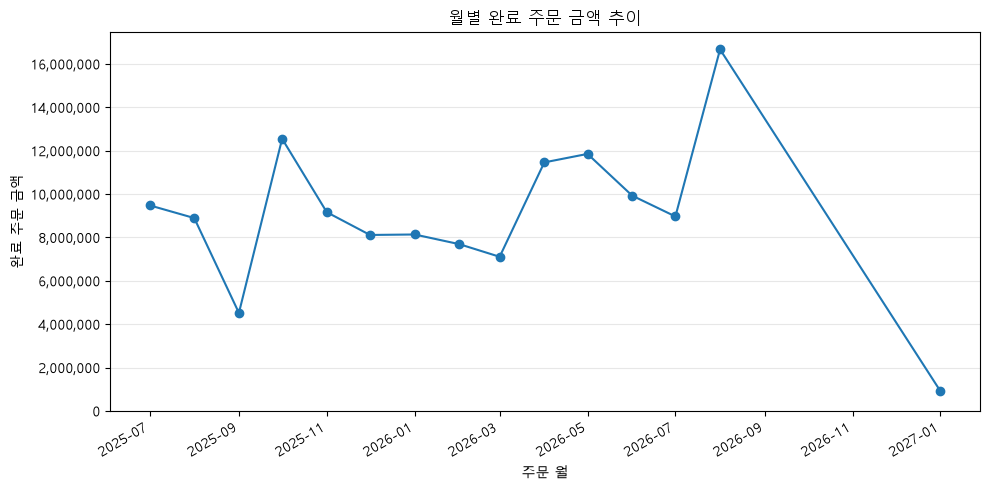

WindowsPath('C:/Users/yjun0/Desktop/서울대/4학년/2학기/LLM을 이용한 빅데이터 분석/llm-data-analysis-course/reports/figures/ch07_monthly_completed_amount_line.png')

In [8]:
monthly_path = plot_monthly_sales(
    monthly_sales,
    FIGURE_DIR / "ch07_monthly_completed_amount_line.png",
    show=True,
)
monthly_path

In [9]:
# 선그래프가 빈 달을 직선으로 이어버리는지 확인
month_index = pd.period_range(monthly_sales["order_month"].min(), monthly_sales["order_month"].max(), freq="M")
missing_months = month_index.difference(monthly_sales["order_month"])

print("그래프 x축 범위:", month_index.min(), "~", month_index.max(), f"({len(month_index)}개월)")
print("실제 데이터가 있는 달:", len(monthly_sales))
print("데이터가 없는 달:", len(missing_months))
monthly_sales.tail(4)[["order_month", "completed_amount", "completed_order_count"]]

그래프 x축 범위: 2025-07 ~ 2027-01 (19개월)
실제 데이터가 있는 달: 15
데이터가 없는 달: 4


,order_month,completed_amount,completed_order_count
11,2026-06,9926000.0,16
12,2026-07,8966000.0,8
13,2026-08,16668000.0,15
14,2027-01,909000.0,1


### 그래프 2 기록

- **관찰:** 2026-08이 16668000으로 가장 높고, 2027-01을 빼면 2025-09가 4519000으로 가장 낮다. 마지막 점 2027-01은 909000이다.
- **해석:** 2025-09가 낮은 건 주문 수가 4건뿐이라서다. 평균 주문 금액은 1129750으로 오히려 높은 편이다. 2026-08은 주문 수 15건, 평균 1111200으로 둘 다 높았다.
- **한계:** 월 주문 수가 4건에서 17건이라 한두 건에 크게 흔들린다. 프로모션이나 계절 정보가 없어서 왜 오르내렸는지는 말할 수 없다.
- **다음 질문:** 2026-08 금액을 올린 게 특정 카테고리나 특정 주문 몇 건인가?

## 3. 대표 그래프 2
![대표 그래프 2](images/graph02.png)

### 원본 집계값

| order_month | completed_amount | 주문 수 | 평균 주문 금액 |
| --- | ---: | ---: | ---: |
| 2025-07 | 9479000 | 11 | 861727 |
| 2025-08 | 8892000 | 17 | 523059 |
| 2025-09 | 4519000 | 4 | 1129750 |
| 2025-10 | 12547000 | 17 | 738059 |
| 2025-11 | 9163000 | 16 | 572688 |
| 2025-12 | 8113000 | 12 | 676083 |
| 2026-01 | 8135000 | 9 | 903889 |
| 2026-02 | 7689000 | 12 | 640750 |
| 2026-03 | 7107000 | 13 | 546692 |
| 2026-04 | 11459000 | 14 | 818500 |
| 2026-05 | 11850000 | 12 | 987500 |
| 2026-06 | 9926000 | 16 | 620375 |
| 2026-07 | 8966000 | 8 | 1120750 |
| 2026-08 | 16668000 | 15 | 1111200 |
| 2027-01 | 909000 | 1 | 909000 |

합계 135422000. 날짜가 비어 있는 completed 6행 1903000은 월을 정할 수 없어서 빠졌다. 검증표의 monthly_completed_amount_valid_dates가 passed True다.

### 결과 관찰

점 15개가 집계표 값과 일치한다. 2026-08에서 가장 높이 올라갔다가 2027-01까지 직선으로 길게 떨어진다. 그 사이 2026-09부터 2026-12까지 4개월은 점이 없다.

### 나의 해석과 판단

마지막 하락 구간은 그래프가 만든 착시라고 판단했다. 2026-09부터 4개월은 completed 주문이 0인 게 아니라 데이터가 아예 없는데, 선그래프가 점과 점을 이어서 계속 떨어진 것처럼 보이게 한다. 2027-01은 order_id 256 한 건이고 Chapter 05에서 미래 날짜로 남겨둔 주문이라 추세에 넣으면 안 된다.

2025-09 최저점도 그대로 읽으면 안 된다. 주문이 4건뿐이라 금액이 낮을 뿐 평균 주문 금액은 1129750으로 오히려 높은 편이다.

### 업무·분석적 의미

이 그래프를 그대로 보고서에 넣으면 하반기 매출이 급감했다고 읽힌다. 실제로 쓸 범위는 2025-07부터 2026-08까지이고, 범위를 잘라 그리거나 빈 달을 따로 표시해야 한다.

### 한계와 추가 확인 사항

월 주문 수가 4건에서 17건이라 주문 한두 건에 금액이 크게 흔들린다. 프로모션이나 계절 정보가 없어서 오르내린 원인은 말할 수 없다. 날짜가 비어 있는 6행 1903000이 실제로 어느 달 주문이었는지도 알 수 없다.

## 5. 상품 가격 분포 — 히스토그램

상품 가격은 상품 마스터의 속성이므로 주문 상태와 무관하게 전체 상품을 봅니다. `bins` 값에 따라 모양이 달라질 수 있으므로 구간 수 하나만 보고 이상값을 확정하지 않습니다.

In [10]:
from src.visualization import plot_product_price_hist

products["price"].describe()

count    9.600000e+01
mean     2.048958e+05
std      1.011848e+06
min      5.000000e+03
25%      5.275000e+04
50%      9.450000e+04
75%      1.532500e+05
max      9.999999e+06
Name: price, dtype: float64

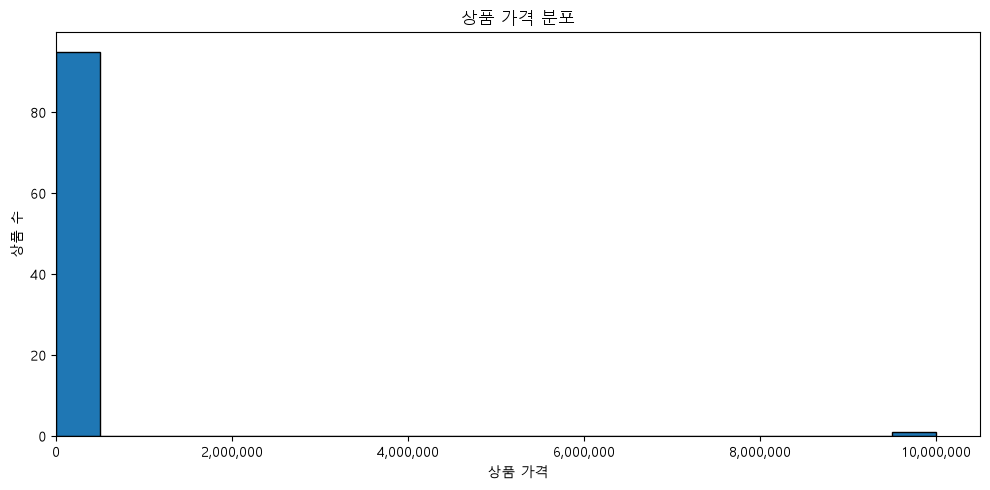

WindowsPath('C:/Users/yjun0/Desktop/서울대/4학년/2학기/LLM을 이용한 빅데이터 분석/llm-data-analysis-course/reports/figures/ch07_product_price_hist.png')

In [11]:
price_hist_path = plot_product_price_hist(
    products,
    FIGURE_DIR / "ch07_product_price_hist.png",
    show=True,
    bins=20,
)
price_hist_path

### bins 비교 실습

`bins=10`, `20`, `30`으로 바꾸어 같은 데이터가 어떻게 다르게 보이는지 비교합니다.

- 어떤 공통 패턴이 유지되는가? 세 그래프 모두 상품 95개가 첫 막대 하나에 몰리고 10000000 근처에 막대 1개가 따로 떨어져 있다.
- 어떤 인상은 bins 선택에 따라 달라지는가? 거의 달라지지 않았다. bins를 바꿔도 9999999원 상품 1개 때문에 x축이 0에서 10000000까지 늘어나서, 나머지 상품이 들어 있는 0에서 197000 구간은 항상 막대 하나로 보인다. 이 데이터에서는 bins보다 축 범위가 더 큰 문제였다. 9999999원을 빼고 그린 아래 그래프에서야 5000원에서 197000원 사이에 상품이 고르게 퍼져 있는 게 보인다.

bins=10


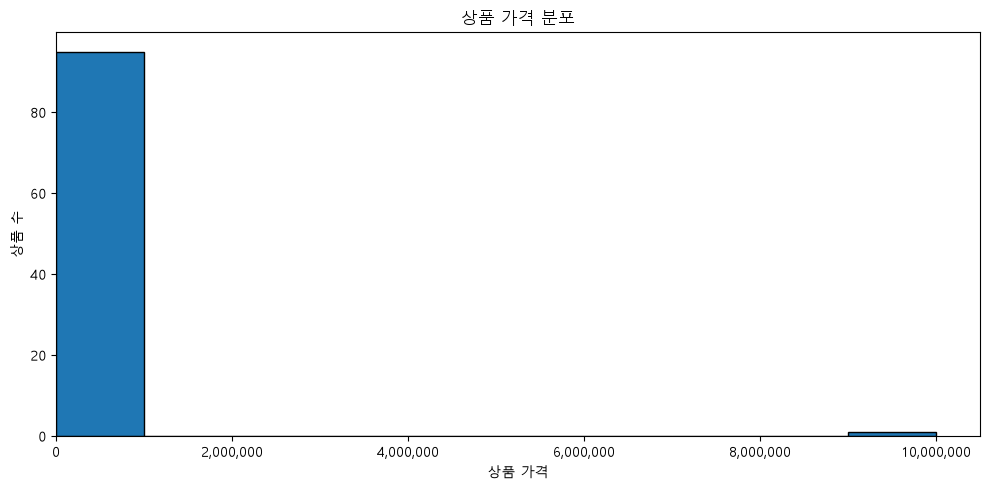

bins=20


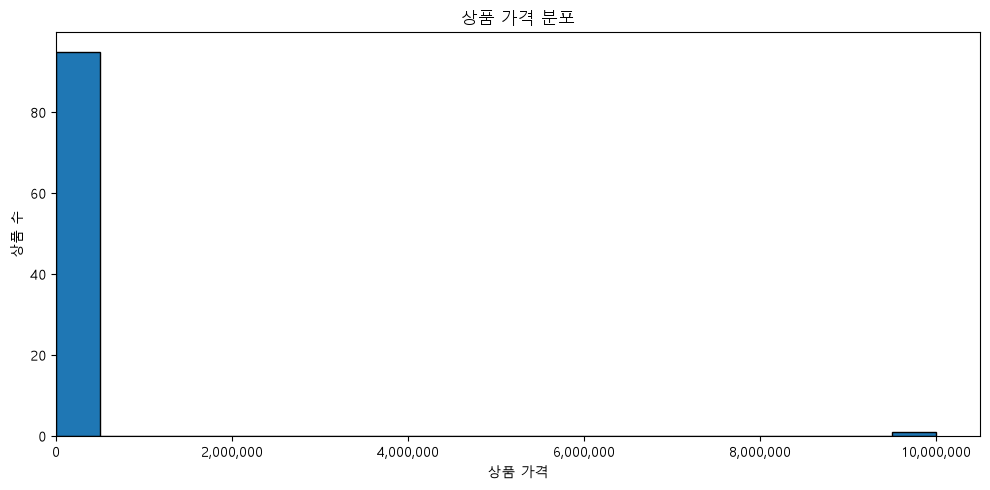

bins=30


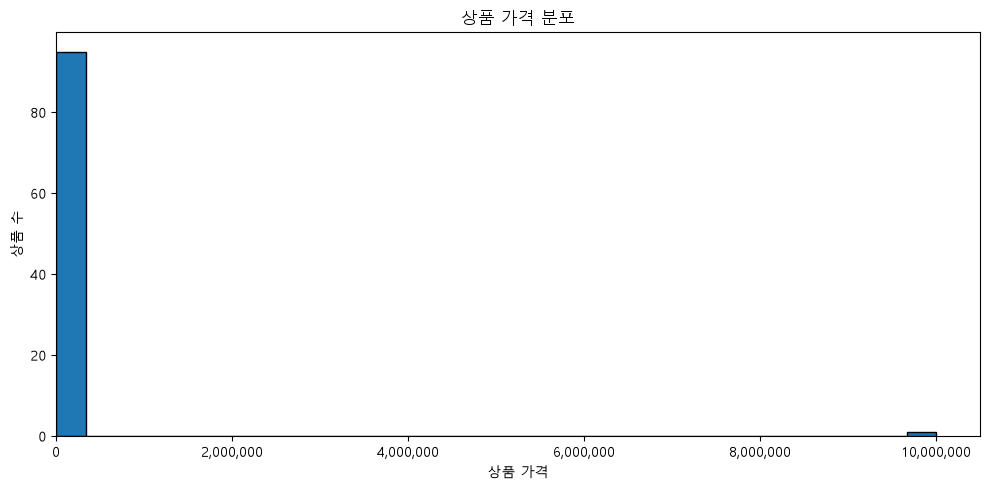

In [12]:
for b in [10, 20, 30]:
    print(f"bins={b}")
    plot_product_price_hist(products, show=True, bins=b)

9999999원 상품 수: 1


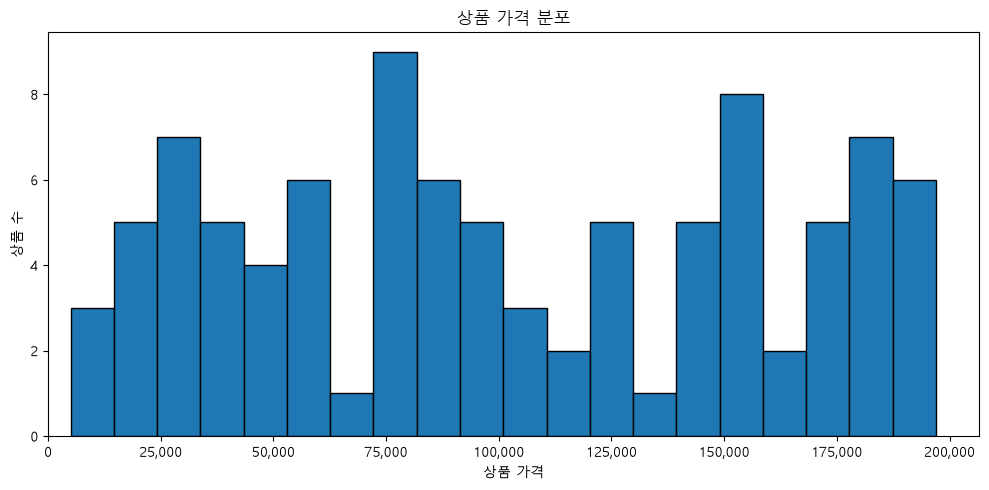

In [13]:
# 9999999원 1건 때문에 축이 늘어나서, 이 상품을 뺀 분포도 같이 본다
print("9999999원 상품 수:", (products["price"] >= 9999999).sum())
plot_product_price_hist(products[products["price"] < 9999999], show=True, bins=20)

## 6. 상품 가격과 완료 주문 판매 수량 — 산점도

한 점은 상품 하나입니다. 관계가 보여도 **가격이 판매 수량의 원인**이라고 단정하지 않습니다.

In [14]:
from src.visualization import plot_price_quantity_scatter

product_sales[["price", "completed_quantity", "completed_amount"]].head(10)

,price,completed_quantity,completed_amount
70,183000.0,37.0,6771000.0
90,96000.0,70.0,6720000.0
91,187000.0,26.0,4862000.0
61,193000.0,22.0,4246000.0
50,152000.0,26.0,3952000.0
66,168000.0,21.0,3528000.0
45,171000.0,19.0,3249000.0
36,172000.0,17.0,2924000.0
47,183000.0,15.0,2745000.0
81,145000.0,18.0,2610000.0


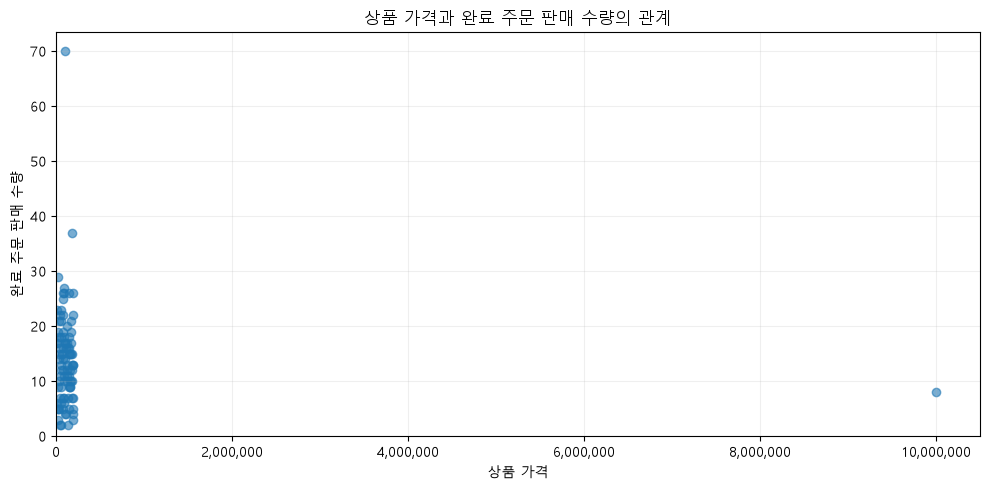

WindowsPath('C:/Users/yjun0/Desktop/서울대/4학년/2학기/LLM을 이용한 빅데이터 분석/llm-data-analysis-course/reports/figures/ch07_price_completed_quantity_scatter.png')

In [15]:
scatter_path = plot_price_quantity_scatter(
    product_sales,
    FIGURE_DIR / "ch07_price_completed_quantity_scatter.png",
    show=True,
)
scatter_path

### 그래프 3 기록

- **관찰:** 점 95개 중 대부분이 x축 왼쪽 끝 200000원 이하에 몰려 있다. 오른쪽 끝 10000000 근처에 점 1개(product 99, 수량 8), 위쪽에 수량 70인 점 1개(product 96)가 떨어져 있다.
- **해석:** 관계는 거의 없어 보인다. 상관계수가 -0.07이고 두 점을 빼면 -0.009다. 가격이 높을수록 덜 팔린다고 말할 근거는 없다.
- **한계:** 카테고리, 할인, 노출, 재고를 보지 않았다. x축은 products.price인데 product 99는 이 값이 9999999이고 실제 주문 단가는 187000이라 점이 실제 판매 가격과 다른 곳에 찍혀 있다.
- **다음 질문:** x축을 실제 판매 단가(unit_price)로 바꾸고, 수량 대신 주문 건수로 보면 패턴이 달라지는가?

## 4. 대표 그래프 3
![대표 그래프 3](images/graph03.png)

### 원본 집계값

- 점 개수: 상품 95개 (completed 판매가 있는 상품)
- 가격 범위: 5000 ~ 197000, 그리고 9999999 한 개 (product 99)
- 판매 수량 상위: product 96 70개, product 75 37개
- price와 completed_quantity 상관계수: 전체 -0.07 / 9999999 제외 -0.014 / product 96까지 제외 -0.009

### 결과 관찰

점 대부분이 x축 왼쪽 200000원 이하 좁은 띠에 몰려 있고 세로로 퍼져 있다. 오른쪽 끝 10000000 근처에 점 하나가 수량 8에 찍혀 있고, 위쪽 수량 70에 점 하나가 떨어져 있다.

### 나의 해석과 판단

가격과 판매 수량 사이에 관계는 거의 없어 보인다. 상관계수가 -0.07이고 튀는 점 두 개를 빼면 -0.009라서, 가격이 높을수록 덜 팔린다고 말할 근거가 없다.

오른쪽 끝 점은 값 자체가 이상하다. product 99는 products.price가 9999999인데 실제 주문의 unit_price는 187000이다. 산점도는 products.price를 x축으로 쓰니까 이 상품은 실제로 팔린 가격과 전혀 다른 위치에 찍혀 있다. 이 점 하나 때문에 x축이 50배 늘어나 나머지 94개 점이 왼쪽에 붙어버렸다.

위쪽 점 product 96의 70개 중 50개는 order_id 290 한 건이다. 한 번의 대량 주문이 상품 전체 판매 수량을 끌어올린 것이다.

### 업무·분석적 의미

이 그래프로 가격 정책을 판단하면 안 된다. 관계가 약한 데다 축 범위가 잘못된 값 하나에 끌려가 있어서, 보는 사람이 실제 분포를 볼 수 없다.

### 한계와 추가 확인 사항

카테고리, 할인, 노출, 재고를 하나도 보지 않았다. 가격대가 비슷해도 카테고리마다 팔리는 양이 다를 수 있다. products.price가 실제 판매 가격과 다를 수 있다는 것도 확인했으니, 다음에는 unit_price를 x축으로 쓰고 수량 대신 주문 건수를 같이 봐야 할 것 같다.

## 7. 완료 주문 구매 금액 상위 고객 — 익명 가로 막대그래프

공개 그래프에서는 고객 이름이나 원본 고객 ID를 직접 표시하지 않고 **순위 기반 익명 라벨**을 사용합니다. Top 10은 전체 고객 분포가 아니라 일부 고객만 보여 줍니다.

In [16]:
from src.visualization import plot_top_customers

customer_sales[
    ["customer_id", "completed_order_count", "completed_amount", "average_completed_order_amount"]
].head(10)

,customer_id,completed_order_count,completed_amount,average_completed_order_amount
1,3,3,6702000.0,2234000.0
7,14,4,5122000.0,1280500.0
57,90,3,4311000.0,1437000.0
47,65,6,3977000.0,662833.0
66,104,2,3966000.0,1983000.0
59,93,4,3845000.0,961250.0
11,20,4,3808000.0,952000.0
27,38,4,3656000.0,914000.0
19,28,4,3201000.0,800250.0
55,85,4,2832000.0,708000.0


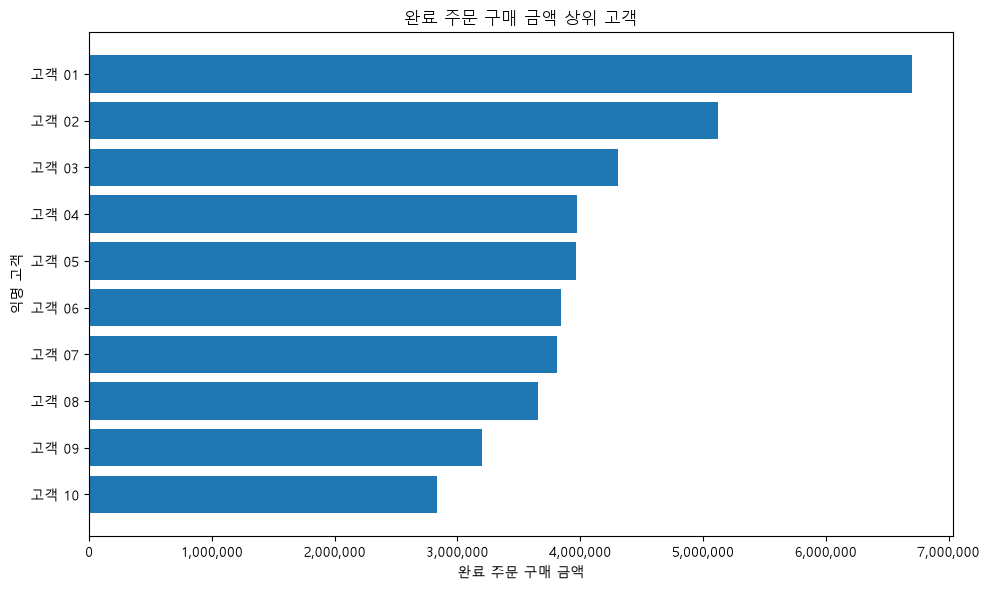

WindowsPath('C:/Users/yjun0/Desktop/서울대/4학년/2학기/LLM을 이용한 빅데이터 분석/llm-data-analysis-course/reports/figures/ch07_top_customers_anonymized_barh.png')

In [17]:
top_customer_path = plot_top_customers(
    customer_sales,
    FIGURE_DIR / "ch07_top_customers_anonymized_barh.png",
    show=True,
    top_n=10,
)
top_customer_path

### 해석 주의

구매 금액이 높다고 바로 '충성 고객'이라고 부르지 않습니다.

- 반복 주문 횟수는 많은가?
- 한 번의 큰 주문 때문인가?
- 평균 주문 금액은 어떤가?
- 분석 기간이 충분한가?

그래프의 고객 01(customer_id 3)은 completed 금액 6702000 중 4800000이 order_id 290 한 건에서 나왔다. 이 주문은 product 96을 50개 산 건이다. 주문 3건 중 1건이 대부분이라 반복 구매로 보기 어렵다. Chapter 06에서 1위였던 고객은 quantity 100 주문이 refunded라 completed 범위에서는 빠졌다.

## 8. 전체 주문 상태 — 막대그래프

이 그래프만 전체 주문을 사용합니다. 상태별 규모는 보여 주지만 취소·환불의 원인을 설명하지 않습니다.

In [18]:
from src.visualization import plot_order_status

order_status

,order_status,order_count
0,completed,180
1,cancelled,63
2,refunded,57


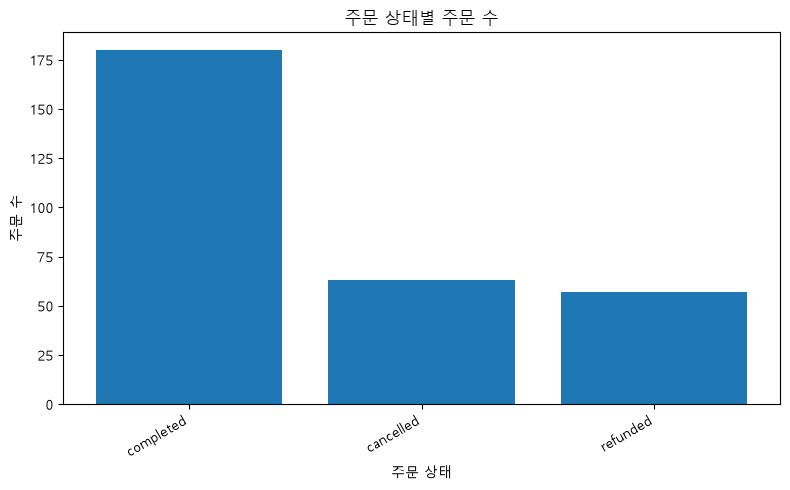

WindowsPath('C:/Users/yjun0/Desktop/서울대/4학년/2학기/LLM을 이용한 빅데이터 분석/llm-data-analysis-course/reports/figures/ch07_order_status_bar.png')

In [19]:
order_status_path = plot_order_status(
    order_status,
    FIGURE_DIR / "ch07_order_status_bar.png",
    show=True,
)
order_status_path

## 9. 그래프와 숫자를 교차 검증합니다

대표 그래프 3개 이상에 대해 다음을 확인합니다.

```text
그래프에 표시된 값
=
그래프 원본 집계표의 값
```

또한 다음을 점검합니다.

- 축 이름과 단위가 맞는가?
- 범주 정렬과 날짜 정렬이 맞는가?
- 막대그래프 값 축이 불필요하게 잘리지 않았는가?
- 제목이 실제 분석 범위를 반영하는가?
- 데이터가 없는 구간을 임의로 0으로 만들지 않았는가?

## 5. 그래프 정확성 점검
- [x] 그래프 값과 집계표 값 일치
- [x] 축 이름 확인
- [x] 단위 확인
- [x] 범례 확인
- [x] 날짜 정렬 확인
- [x] 과장될 수 있는 축 범위 확인
- [x] 제목이 분석 범위를 정확히 표현

### 내가 발견한 시각화 위험 또는 개선점

선그래프가 데이터가 없는 2026-09부터 2026-12까지를 직선으로 이어서 급감처럼 보이게 한다. 2026-08까지만 그리거나 빈 달을 끊어서 표시하는 게 맞다.

히스토그램과 산점도는 9999999원 상품 하나 때문에 x축이 0에서 10000000까지 늘어난다. bins를 10, 20, 30으로 바꿔도 해결되지 않았고, 그 상품을 빼고 그려야 실제 분포가 보였다. 그런데 이 값은 이상값이라기보다 products.price가 잘못 들어간 경우라서, 그래프에서 빼는 것보다 원본 값을 확인하는 게 먼저다.

카테고리 막대그래프는 띄어쓰기만 다른 이름이 따로 막대가 된다.

제목은 완료 주문 금액이라고 범위를 밝히고 있지만, 관계 오류 18행을 뺀 기준이라는 건 제목이나 축에 나오지 않는다. 범례는 계열이 하나라 따로 없고 필요하지도 않다. 단위는 축 이름에 원이 적혀 있지 않아서 보고서에 넣을 때는 붙여야 한다.

## 10. 공통 함수로 전체 그래프와 보고서를 다시 생성합니다

Notebook에서 개별 그래프를 이해한 뒤 공통 함수를 사용해 같은 결과를 재현합니다.

In [20]:
from src.visualization import (
    build_visualization_report,
    create_all_figures,
    create_visualization_summary,
)

saved_figures = create_all_figures(viz_data, FIGURE_DIR, show=False)
summary = create_visualization_summary()

summary_path = REPORT_DIR / "ch07_visualization_summary.md"
summary_path.write_text(
    build_visualization_report(summary),
    encoding="utf-8",
)

print("생성 파일")
for path in saved_figures:
    print("-", path)

print("요약 보고서:", summary_path)
summary

생성 파일
- C:\Users\yjun0\Desktop\서울대\4학년\2학기\LLM을 이용한 빅데이터 분석\llm-data-analysis-course\reports\figures\ch07_category_completed_amount_bar.png
- C:\Users\yjun0\Desktop\서울대\4학년\2학기\LLM을 이용한 빅데이터 분석\llm-data-analysis-course\reports\figures\ch07_monthly_completed_amount_line.png
- C:\Users\yjun0\Desktop\서울대\4학년\2학기\LLM을 이용한 빅데이터 분석\llm-data-analysis-course\reports\figures\ch07_product_price_hist.png
- C:\Users\yjun0\Desktop\서울대\4학년\2학기\LLM을 이용한 빅데이터 분석\llm-data-analysis-course\reports\figures\ch07_price_completed_quantity_scatter.png
- C:\Users\yjun0\Desktop\서울대\4학년\2학기\LLM을 이용한 빅데이터 분석\llm-data-analysis-course\reports\figures\ch07_top_customers_anonymized_barh.png
- C:\Users\yjun0\Desktop\서울대\4학년\2학기\LLM을 이용한 빅데이터 분석\llm-data-analysis-course\reports\figures\ch07_order_status_bar.png
요약 보고서: C:\Users\yjun0\Desktop\서울대\4학년\2학기\LLM을 이용한 빅데이터 분석\llm-data-analysis-course\reports\ch07_visualization_summary.md


,chart,question,scope,interpretation_point,file_name
0,카테고리별 완료 주문 금액,카테고리별 완료 주문 금액은 어떻게 다른가?,completed orders,금액 차이는 수량·단가 등 추가 지표로 확인,ch07_category_completed_amount_bar.png
1,월별 완료 주문 금액,월별 완료 주문 금액은 어떻게 변하는가?,completed orders + valid order_date,증감은 관찰이며 원인은 추가 데이터 필요,ch07_monthly_completed_amount_line.png
2,상품 가격 분포,상품 가격은 어떤 구간에 몰려 있는가?,product master,상품 구성 분포이며 판매 선호를 의미하지 않음,ch07_product_price_hist.png
3,상품 가격과 완료 주문 판매 수량,상품 가격과 완료 주문 판매 수량은 어떤 패턴을 보이는가?,completed orders aggregated by product,관계는 인과를 의미하지 않음,ch07_price_completed_quantity_scatter.png
4,완료 주문 구매 금액 상위 고객,완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가?,completed orders aggregated by customer,Top N이며 충성도를 자동 의미하지 않음,ch07_top_customers_anonymized_barh.png
5,주문 상태별 주문 수,주문 상태별 주문 수는 어떻게 다른가?,all orders,상태 분포만으로 취소·환불 원인을 알 수 없음,ch07_order_status_bar.png


## 11. Chapter 07 최종 판단

아래 내용을 직접 작성합니다.

### 가장 중요한 그래프 1개와 이유

월별 완료 주문 금액 선그래프다. 그래프만 보면 2026-08 이후 급감한 것처럼 보이는데 실제로는 데이터가 없는 4개월을 선이 이어버린 것이라서, 그래프가 오해를 만드는 경우를 가장 분명하게 보여줬다.

### 그래프에서 직접 확인한 사실

월별 completed 금액은 2025-09에 4519000으로 가장 낮고 2026-08에 16668000으로 가장 높다. 2026-09부터 2026-12까지는 completed 주문이 하나도 없고 2027-01에 1건 909000이 있다.

### 내가 해석한 내용

2027-01 점은 Chapter 05에서 미래 날짜로 남겨둔 주문이라 추세에 넣으면 안 된다고 봤다. 실제 비교 범위는 2025-07부터 2026-08까지 14개월이다.

### 그래프만으로 말할 수 없는 것

월별 금액이 왜 오르내렸는지는 말할 수 없다. 주문 수가 적은 달은 주문 한두 건에 크게 바뀐다.

### 오해를 줄이기 위해 수정하거나 확인한 요소
- 축: 막대와 선그래프의 y축이 0에서 시작하는지 확인했다. 히스토그램과 산점도의 x축은 9999999원 상품 하나 때문에 50배로 늘어나 있다.
- 단위: 금액은 원 단위이고 축 눈금에 천 단위 구분이 들어가 있다. 축 이름에 단위가 따로 적혀 있지는 않다.
- 정렬: 카테고리는 금액 내림차순, 월은 시간 순서로 정렬된 걸 확인했다.
- 범위: 금액 그래프는 전부 completed 주문만이고, 관계 오류 18행을 뺀 기준이다. 월별은 날짜 결측 6행 1903000이 추가로 빠진다.
- 개인정보: 고객 그래프는 이름 대신 고객 01 같은 익명 라벨만 쓴다.

### 다음 분석에서 확인하고 싶은 질문

카테고리 표기를 정리하고 빠진 4015000의 카테고리를 찾으면 4위와 5위 순서가 어떻게 되는가?

---

## 완료 체크

- [x] 질문을 그래프보다 먼저 정했습니다.
- [x] 금액성 그래프에 `completed` 주문 범위를 적용했습니다.
- [x] 집계 검증표의 `passed`를 확인했습니다.
- [x] 대표 그래프 3개 이상을 만들었습니다.
- [x] 그래프와 원본 집계값을 교차 확인했습니다.
- [x] 축·단위·정렬·범위를 확인했습니다.
- [x] 관계를 원인으로 단정하지 않았습니다.
- [x] 고객 그래프에서 개인정보를 직접 노출하지 않았습니다.
- [x] 그래프별 관찰·해석·한계·다음 질문을 작성했습니다.
- [x] `reports/figures`와 요약 보고서가 재생성되는지 확인했습니다.

다음 Chapter 08에서는 전처리, EDA, 시각화와 보고서를 하나의 작은 분석 프로젝트로 연결합니다.

## 6. Chapter 07 최종 판단
### 가장 중요한 그래프 1개와 이유

월별 완료 주문 금액 선그래프다. 집계값은 정확한데도 그래프 모양 때문에 틀린 결론이 나올 수 있다는 걸 가장 분명하게 보여줬다. 숫자를 검증하는 것만으로는 부족하고 그래프가 그 숫자를 어떻게 보여주는지까지 봐야 한다는 걸 이 그래프에서 확인했다.

### 그래프가 보여 준 사실

completed 금액은 패션, 식품, 전자기기 순으로 크고, 월별로는 2026-08이 가장 높다. 상품 가격과 판매 수량 사이에는 뚜렷한 관계가 보이지 않는다.

### 그래프만으로 말할 수 없는 것

카테고리 금액 차이가 수량 때문인지 단가 때문인지, 월별 금액이 왜 오르내렸는지는 말할 수 없다. 카테고리 4위와 5위 순서처럼 표기 정리나 제외한 4015000에 따라 바뀔 수 있는 것도 결론으로 쓸 수 없다.

### 다음 분석에서 확인할 질문

카테고리 표기를 상품명 기준으로 정리하고, 상품 정보가 없어 빠진 completed 4015000의 카테고리를 찾으면 순위가 어떻게 바뀌는가? 산점도의 x축을 실제 판매 단가로 바꾸면 가격과 판매량 관계가 달라 보이는가?

## 최종 체크
- [x] 그래프와 수치를 교차 검증했습니다.
- [x] 관찰과 해석을 구분했습니다.
- [x] 업무적 의미와 한계를 작성했습니다.
- [x] 최종 Notebook URL을 제출합니다.